# Heat diffusion on a 2-D grid

A plate is warm in the middle and its edge is held cold. Each grid cell moves toward the average of its four
neighbours, and the warmth spreads out. This is the textbook explicit heat step, and it is a stencil: every cell reads
the cells around it.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, plot_style, show, to_numpy, xp
plot_style()

## The step, one cell at a time

A `Grid` names the lane axes: here `row` and `col`. A bare label (`"row"`) is sized when you run the kernel (`row=N`
below), and only the first axis may be bare; `"col":width` fixes that axis in the kernel. The last axis declared is the
fastest: consecutive lanes run along `col`, so on a GPU neighbouring threads read neighbouring memory, and on a CPU they
fill the SIMD lanes. `u.at(row=i - 1, col=j)` reads
the cell above, and so on. The cells on the edge have no neighbour on one side, so the body picks the edge value
with an `if`/`else` and returns once at the end.

The step is `u + r * (up + down + left + right - 4 u)`, with `r = alpha dt / dx^2`. The explicit scheme is stable for
`r <= 0.25`. The quantities are dimensionless: lengths in cells, time in steps, diffusivity 1 on a unit plate.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Grid, Param, Scalar


def heat_kernel(width):
    @hawk.kernel
    def heat_step(lane: Grid["row", "col":width], u: Scalar, r: Param) -> Scalar:
        i, j = lane.row, lane.col
        if m.land(m.land(i > 0, i < width - 1), m.land(j > 0, j < width - 1)):
            out = u + r * (u.at(row=i - 1, col=j) + u.at(row=i + 1, col=j)
                           + u.at(row=i, col=j - 1) + u.at(row=i, col=j + 1) - 4.0 * u)
        else:
            out = 0.0                    # the edge is held at zero
        return out
    return eagle.deploy(heat_step)


def blob(width):
    """Zero everywhere except a warm square in the middle."""
    u = np.zeros((width, width))
    c, k = width // 2, width // 8
    u[c - k:c + k, c - k:c + k] = 1.0
    return u


N, R = 48, 0.2
step = heat_kernel(N)
u0 = blob(N)
u1 = step.run(u=u0, r=R, row=N)
u1.shape

(48, 48)

## Check one step against NumPy

The same step written with array slices gives the answer to compare with.

In [4]:
def numpy_step(u, r):
    out = np.zeros_like(u)
    out[1:-1, 1:-1] = u[1:-1, 1:-1] + r * (u[:-2, 1:-1] + u[2:, 1:-1] + u[1:-1, :-2] + u[1:-1, 2:] - 4.0 * u[1:-1, 1:-1])
    return out


TOL = 1e-12
err = np.abs(u1 - numpy_step(u0, R)).max()
assert err < TOL, err
print(f"one step: largest difference from NumPy {err:.1e} < {TOL:g}")

one step: largest difference from NumPy 0.0e+00 < 1e-12


## Run it

Feed each result back in as the next input. Two arrays (copies of the start, so the start stays intact) take turns.
`step.bind(...)` ties one launch to its input and output arrays. We bind twice: `forward` reads `a` and writes `b`,
`backward` reads `b` and writes `a`. A step is then one `.launch()`, alternating the two. On a GPU the arrays live on the device for the whole run and only the
frames we keep come home (`xp` is CuPy there, NumPy otherwise).

The warmth can only leave through the cold edge, so the total heat must fall. The run adds up what crosses the edge
step by step, on the device, and once per frame checks that the total dropped by exactly that, and that the field
stayed between its start values (0 and 1).

In [5]:
steps_per_frame, n_frames = 8, 36
a, b = xp.array(u0), xp.zeros((N, N))
forward = step.bind(u=a, out=b, r=R, row=N)       # a -> b
backward = step.bind(u=b, out=a, r=R, row=N)      # b -> a
launches, arrays, which = (forward, backward), (a, b), 0
frames, total = [u0], [u0.sum()]
for _ in range(n_frames - 1):
    lost = xp.zeros(())
    for _ in range(steps_per_frame):
        src = arrays[which]
        lost += R * (src[1, 1:-1].sum() + src[-2, 1:-1].sum() + src[1:-1, 1].sum() + src[1:-1, -2].sum())
        launches[which].launch()
        which = 1 - which
    u = arrays[which]
    assert abs(total[-1] - float(u.sum()) - float(lost)) < 1e-9, "heat leaves only through the edge"
    assert 0.0 <= float(u.min()) and float(u.max()) <= 1.0, "the field stays between its start values"
    frames.append(to_numpy(u).copy())
    total.append(float(u.sum()))

u = to_numpy(u)
total = np.array(total)
assert np.all(np.diff(total) <= 1e-12), "heat must not grow"
print(f"total heat: {total[0]:.2f} -> {total[-1]:.2f}; peak {u0.max():.2f} -> {u.max():.2f}")

total heat: 144.00 -> 124.67; peak 1.00 -> 0.18


## Check the physics

Matching NumPy tests the code, not the equation. The lowest sine mode `sin(pi x) sin(pi y)` has a known fate: each step
multiplies it by exactly `g = 1 - 8 r sin^2(pi / (2 (N - 1)))`, and over time `t` the true heat equation damps it by
`exp(-2 pi^2 t)`. The loop above also checked, at every step, that the heat lost equals `r` times the cells next to the
edge, and that the field stayed between 0 and 1.

In [6]:
x = np.arange(N) / (N - 1)
mode = np.outer(np.sin(np.pi * x), np.sin(np.pi * x))
g = 1 - 8 * R * np.sin(np.pi / (2 * (N - 1))) ** 2
n_steps = 280                                          # even, so the result is back in `a`
a, b = xp.array(mode), xp.zeros((N, N))
forward = step.bind(u=a, out=b, r=R, row=N)
backward = step.bind(u=b, out=a, r=R, row=N)
for _ in range(n_steps // 2):
    forward.launch()
    backward.launch()
TOL_MODE = 1e-12
assert np.abs(to_numpy(a) - g ** n_steps * mode).max() < TOL_MODE
t = n_steps * R / (N - 1) ** 2
print(f"mode after {n_steps} steps: {g ** n_steps:.4f} of its start; continuum exp(-2 pi^2 t) = {np.exp(-2 * np.pi ** 2 * t):.4f}")

mode after 280 steps: 0.6061 of its start; continuum exp(-2 pi^2 t) = 0.6063


The field at the start and at the end:


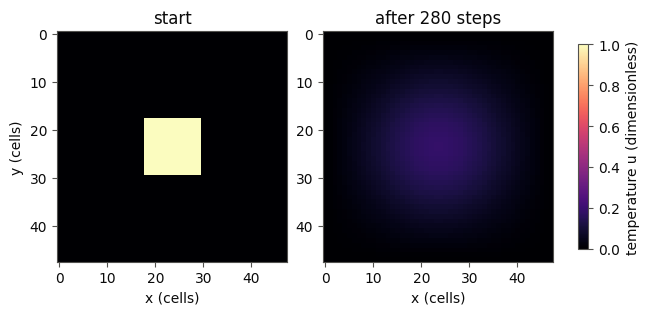
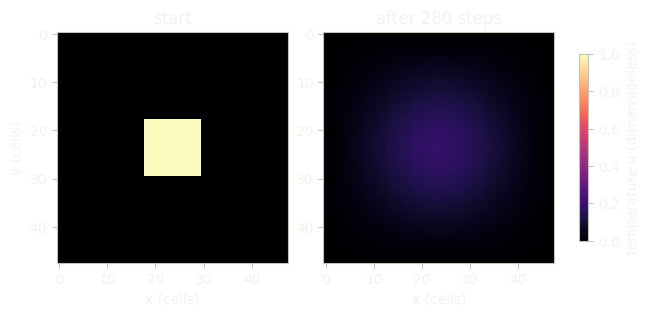

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.0), constrained_layout=True)
for ax, f, title in zip(axes, (frames[0], frames[-1]), ("start", f"after {steps_per_frame * (n_frames - 1)} steps")):
    im = ax.imshow(f, vmin=0, vmax=1, cmap="magma")
    ax.set_title(title); ax.set_xlabel("x (cells)")
axes[0].set_ylabel("y (cells)")
fig.colorbar(im, ax=axes, shrink=0.8, label="temperature u (dimensionless)")
show()

## A bigger grid, when a GPU is there

The width is part of the kernel, so the larger grid is the same function called with a larger number. Where the data
lies decides where the kernel runs: a NumPy array runs on the host, a CuPy array on the GPU. So here the input is handed
over as a device array, and the result comes back as one; the check against NumPy copies it home first. To choose a side yourself, use `step.host.run(...)` or `step.device.run(...)`: the device plan takes NumPy
arrays, uploads them, runs on the GPU and brings the result home.

In [8]:
if gpu_available():
    big = 1024
    big_step = heat_kernel(big)
    ub = blob(big)
    got = big_step.run(u=xp.asarray(ub), r=R, row=big)
    assert type(got).__module__.startswith("cupy"), "the result is a device array: the kernel ran on the GPU"
    err = np.abs(to_numpy(got) - numpy_step(ub, R)).max()
    assert err < TOL, err
    print(f"{big} x {big} on the GPU (result is a {type(got).__module__} array): largest difference from NumPy {err:.1e}")
else:
    print("no GPU here; the grid stays at", N, "x", N)

1024 x 1024 on the GPU (result is a cupy array): largest difference from NumPy 0.0e+00


## The animation

The last cell writes the frames as a looping GIF, one for a light page and one for a dark page. The page below shows the file that was written when the notebook
last ran.

In [9]:
import matplotlib.pyplot as plt
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT


def render(theme, field, label):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(2.6, 2.8), dpi=80, facecolor=pal["bg"])
    ax = fig.add_axes([0.04, 0.12, 0.92, 0.84])
    ax.axis("off")
    ax.imshow(field, vmin=0.0, vmax=1.0, cmap="magma", interpolation="nearest")
    fig.text(0.5, 0.04, label, ha="center", fontsize=9, color=pal["sub"])
    return frame_of(fig, pal["bg"])


for theme in ("light", "dark"):
    movie = [render(theme, f, f"step {k * steps_per_frame}") for k, f in enumerate(frames)]
    for name, size in write_anim(movie, "heat_diffusion_" + theme).items():
        print(name, f"{size / 1e3:.0f} kB")

heat_diffusion_light.gif 175 kB


heat_diffusion_dark.gif 175 kB


```{image} ../../_static/anim/heat_diffusion_light.gif
:class: only-light
:alt: Heat spreading from a warm square in the middle of a plate whose edge is held cold
```
```{image} ../../_static/anim/heat_diffusion_dark.gif
:class: only-dark
:alt: Heat spreading from a warm square in the middle of a plate whose edge is held cold
```

## What just happened

- `Grid["row", "col":N]` named the two axes; `u.at(row=..., col=...)` read the neighbours.
- The edge cells took their value from the `else` branch; the body returns once.
- One step matched NumPy to rounding, and the total heat only fell, by exactly what crossed the edge.
- The lowest sine mode decayed by the exact predicted factor, within 3e-4 of the continuum.

## Next

[Fluids](10_fluids) moves a conserved quantity across the same kind of grid.